Consensus reached at step 1


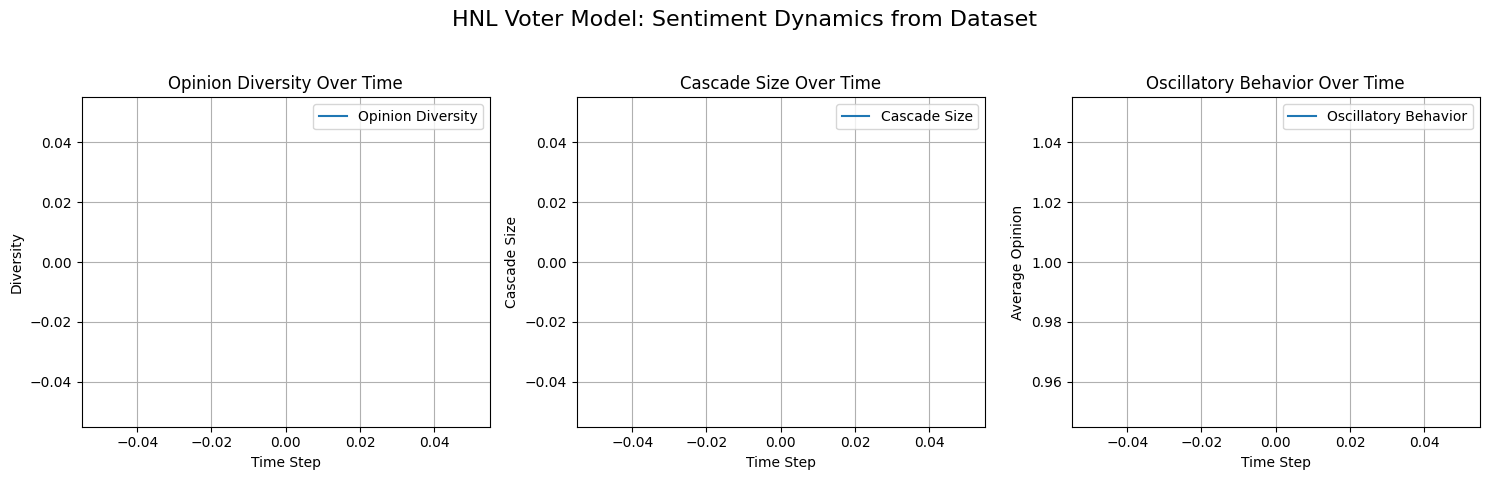

Model saved successfully to hnl_voter_model_trained.json


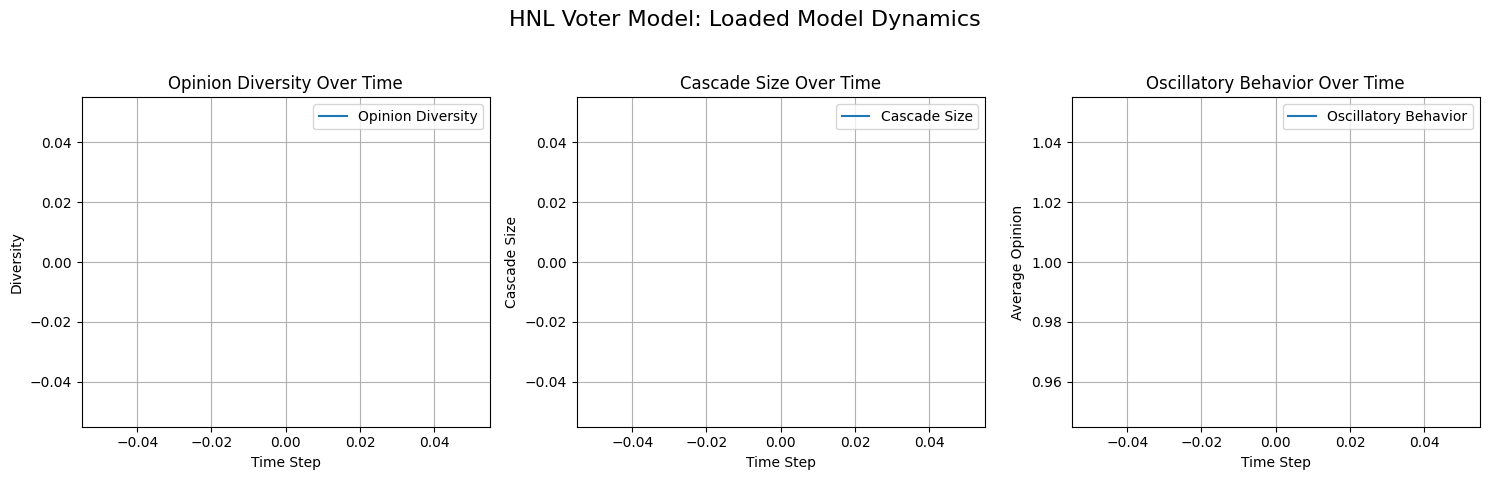

In [2]:
import json
import logging
import random
from collections import defaultdict
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.ensemble import GradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from torch import nn, optim

# Set up logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

# Neural Network for Opinion Prediction
class OpinionPredictor(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 3)  # Output: 3 classes (Negative, Neutral, Positive)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return self.softmax(x)

class HNLVoterModel:
    def __init__(self, nodes: np.ndarray, hyperedges: list[list[int]], influence_weights: np.ndarray, q: float, 
                 latencies: np.ndarray, consensus_threshold: float, sentiment_mapping: dict[str, int] = None, 
                 random_seed: int = None, use_ml_for_updates: bool = False):
        if random_seed is not None:
            np.random.seed(random_seed)
            random.seed(random_seed)
            torch.manual_seed(random_seed)

        self.nodes = np.array(nodes)
        self.hyperedges = [list(edge) for edge in hyperedges if len(edge) > 1]
        self.influence_weights = np.array(influence_weights)
        self.q = q
        self.latencies = np.array(latencies)
        self.consensus_threshold = consensus_threshold
        self.sentiment_mapping = sentiment_mapping or self._default_sentiment_mapping()
        self.opinions = np.zeros(len(nodes), dtype=int)
        self.last_change_time = np.zeros(len(nodes))
        self.time_step = 0
        self.history = []
        self.node_to_user = {}
        self.use_ml_for_updates = use_ml_for_updates

        if self.use_ml_for_updates:
            self.opinion_predictor = OpinionPredictor(input_dim=4)  # Features: current opinion, avg neighbor opinion, influence, hyperedge size
            self.optimizer = optim.Adam(self.opinion_predictor.parameters(), lr=0.001)
            self.criterion = nn.CrossEntropyLoss()

        self._validate_inputs()
        logger.info(f"Model initialized with {len(self.nodes)} nodes and {len(self.hyperedges)} hyperedges.")

    def _default_sentiment_mapping(self) -> dict[str, int]:
        return {
            'Positive': 2, 'Happy': 2, 'Joy': 2, 'Happiness': 2, 'Love': 2, 'Amusement': 2, 'Enjoyment': 2, 
            'Admiration': 2, 'Affection': 2, 'Awe': 2, 'Surprise': 2, 'Adoration': 2, 'Anticipation': 2, 
            'Calmness': 2, 'Excitement': 2, 'Kind': 2, 'Pride': 2, 'Acceptance': 2, 'Elation': 2, 'Euphoria': 2, 
            'Contentment': 2, 'Serenity': 2, 'Gratitude': 2, 'Hope': 2, 'Empowerment': 2, 'Compassion': 2, 
            'Tenderness': 2, 'Arousal': 2, 'Enthusiasm': 2, 'Fulfillment': 2, 'Reverence': 2, 'Satisfaction': 2, 
            'Curiosity': 2, 'Mischievous': 2, 'Neutral': 1, 'Indifference': 1, 'Negative': 0, 'Anger': 0, 'Fear': 0, 
            'Sadness': 0, 'Disgust': 0, 'Disappointed': 0, 'Bitter': 0, 'Confusion': 0, 'Shame': 0, 'Despair': 0, 
            'Grief': 0, 'Loneliness': 0, 'Jealousy': 0, 'Resentment': 0, 'Frustration': 0, 'Boredom': 0, 'Anxiety': 0, 
            'Intimidation': 0, 'Helplessness': 0, 'Envy': 0, 'Regret': 0, 'Hate': 0, 'Bad': 0, 'Sad': 0, 'Embarrassed': 0
        }

    def _validate_inputs(self):
        try:
            assert len(self.nodes) == len(self.influence_weights) == len(self.latencies), \
                "Nodes, influence weights, and latencies must have the same length."
            assert all(isinstance(edge, list) and len(edge) > 1 for edge in self.hyperedges), \
                "Hyperedges must be non-empty lists with at least 2 nodes."
            assert all(all(node in self.nodes for node in edge) for edge in self.hyperedges), \
                "All nodes in hyperedges must exist in nodes array."
            assert self.q >= 0, "Non-linearity parameter q must be non-negative."
            assert 0.5 <= self.consensus_threshold <= 1, "Consensus threshold must be in [0.5, 1]."
            assert all(self.latencies >= 1), "Latencies must be at least 1."
        except AssertionError as e:
            logger.error(f"Validation failed: {e!s}")
            raise

    def compute_influence_scores(self, edge: list[int]) -> dict[int, float]:
        scores = defaultdict(float)
        for j in edge:
            opinion = self.opinions[j]
            scores[opinion] += self.influence_weights[j]
        return scores

    def update_opinions(self):
        new_opinions = self.opinions.copy()
        for edge in self.hyperedges:
            if self.use_ml_for_updates:
                for node in edge:
                    if self.time_step - self.last_change_time[node] >= self.latencies[node]:
                        neighbor_opinions = [self.opinions[n] for n in edge if n != node]
                        avg_neighbor_opinion = np.mean(neighbor_opinions) if neighbor_opinions else 1
                        features = torch.tensor([
                            float(self.opinions[node]),
                            float(avg_neighbor_opinion),
                            float(self.influence_weights[node]),
                            float(len(edge))
                        ], dtype=torch.float32).unsqueeze(0)
                        self.opinion_predictor.eval()
                        with torch.no_grad():
                            probs = self.opinion_predictor(features)
                            new_opinions[node] = torch.argmax(probs, dim=1).item()
                        if new_opinions[node] != self.opinions[node]:
                            self.last_change_time[node] = self.time_step
                            logger.debug(f"Node {node} ({self.node_to_user.get(node, 'Unknown')}) changed opinion to {new_opinions[node]} at step {self.time_step} (ML)")
            else:
                scores = self.compute_influence_scores(edge)
                transformed_scores = {opinion: score ** self.q for opinion, score in scores.items()}
                total_influence = sum(transformed_scores.values())
                for node in edge:
                    if self.time_step - self.last_change_time[node] >= self.latencies[node]:
                        if total_influence == 0:
                            new_opinions[node] = random.choice([0, 1, 2])
                        else:
                            probs = {opinion: score / total_influence for opinion, score in transformed_scores.items()}
                            opinions = list(probs.keys())
                            probabilities = list(probs.values())
                            new_opinions[node] = np.random.choice(opinions, p=probabilities)
                        if new_opinions[node] != self.opinions[node]:
                            self.last_change_time[node] = self.time_step
                            logger.debug(f"Node {node} ({self.node_to_user.get(node, 'Unknown')}) changed opinion to {new_opinions[node]} at step {self.time_step} (Rule-based)")
        self.opinions = new_opinions

    def compute_metrics(self) -> tuple[float, float, float]:
        opinion_counts = {0: 0, 1: 0, 2: 0}
        for opinion in self.opinions:
            opinion_counts[opinion] += 1
        max_count = max(opinion_counts.values())
        diversity = 1 - max_count / len(self.nodes)
        cascade_size = (
            np.sum(self.opinions != self.history[-1]["opinions"]) / len(self.nodes)
            if self.time_step > 0 and self.history
            else 0
        )
        oscillation = np.mean(self.opinions)
        return diversity, cascade_size, oscillation

    def check_consensus(self) -> bool:
        opinion_counts = {0: 0, 1: 0, 2: 0}
        for opinion in self.opinions:
            opinion_counts[opinion] += 1
        for opinion, count in opinion_counts.items():
            proportion = count / len(self.nodes)
            if proportion >= self.consensus_threshold:
                logger.info(f"Consensus reached for opinion {opinion} (proportion: {proportion:.2f})")
                return True
        return False

    def run_simulation(self, max_steps: int = 100) -> list[dict]:
        logger.info(f"Starting simulation with max_steps={max_steps}")
        for self.time_step in range(1, max_steps + 1):
            diversity, cascade_size, oscillation = self.compute_metrics()
            self.history.append({
                "diversity": diversity,
                "cascade_size": cascade_size,
                "oscillation": oscillation,
                "opinions": self.opinions.tolist()
            })
            logger.debug(f"Step {self.time_step}: Diversity={diversity:.3f}, Cascade Size={cascade_size:.3f}, Oscillation={oscillation:.3f}")
            if self.check_consensus():
                logger.info(f"Simulation stopped at step {self.time_step} due to consensus")
                break
            self.update_opinions()
        return self.history

    def plot_metrics(self, title: str = "HNL Voter Model Dynamics"):
        diversity = [h["diversity"] for h in self.history]
        cascade_size = [h["cascade_size"] for h in self.history]
        oscillation = [h["oscillation"] for h in self.history]
        plt.figure(figsize=(15, 5))
        plt.suptitle(title, fontsize=16)
        plt.subplot(1, 3, 1)
        plt.plot(diversity, label="Opinion Diversity")
        plt.xlabel("Time Step")
        plt.ylabel("Diversity")
        plt.title("Opinion Diversity Over Time")
        plt.grid()
        plt.legend()
        plt.subplot(1, 3, 2)
        plt.plot(cascade_size, label="Cascade Size")
        plt.xlabel("Time Step")
        plt.ylabel("Cascade Size")
        plt.title("Cascade Size Over Time")
        plt.grid()
        plt.legend()
        plt.subplot(1, 3, 3)
        plt.plot(oscillation, label="Oscillatory Behavior")
        plt.xlabel("Time Step")
        plt.ylabel("Average Opinion")
        plt.title("Oscillatory Behavior Over Time")
        plt.grid()
        plt.legend()
        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.savefig('../results/sentiment_dynamics.png')
        plt.close()
        logger.info("Metrics plot saved to ../results/sentiment_dynamics.png")

    def save_model(self, path: str):
        model_state = {
            "nodes": self.nodes.tolist(),
            "hyperedges": self.hyperedges,
            "influence_weights": self.influence_weights.tolist(),
            "q": self.q,
            "latencies": self.latencies.tolist(),
            "consensus_threshold": self.consensus_threshold,
            "opinions": self.opinions.tolist(),
            "last_change_time": self.last_change_time.tolist(),
            "time_step": self.time_step,
            "history": self.history
        }
        try:
            with open(path, 'w') as f:
                json.dump(model_state, f, indent=4)
            logger.info(f"Model saved successfully to {path}")
        except Exception as e:
            logger.error(f"Failed to save model to {path}: {e!s}")
            raise OSError(f"Failed to save model to {path}: {e!s}")

    def save_statistics(self, path: str):
        opinion_counts = {0: 0, 1: 0, 2: 0}
        for opinion in self.opinions:
            opinion_counts[opinion] += 1
        stats = {
            "timestamp": datetime.now().isoformat(),
            "total_steps": self.time_step,
            "final_opinion_distribution": {
                "Negative (0)": opinion_counts[0],
                "Neutral (1)": opinion_counts[1],
                "Positive (2)": opinion_counts[2]
            },
            "consensus_reached": self.check_consensus(),
            "average_diversity": np.mean([h["diversity"] for h in self.history]) if self.history else 0,
            "average_cascade_size": np.mean([h["cascade_size"] for h in self.history]) if self.history else 0
        }
        try:
            with open(path, 'w') as f:
                json.dump(stats, f, indent=4)
            logger.info(f"Statistics saved to {path}")
        except Exception as e:
            logger.error(f"Failed to save statistics to {path}: {e!s}")
            raise OSError(f"Failed to save statistics to {path}: {e!s}")

    @classmethod
    def load_model(cls, path: str, random_seed: int = None):
        try:
            with open(path, 'r') as f:
                model_state = json.load(f)
        except Exception as e:
            logger.error(f"Failed to load model from {path}: {e!s}")
            raise OSError(f"Failed to load model from {path}: {e!s}")
        model = cls(
            nodes=np.array(model_state["nodes"]),
            hyperedges=model_state["hyperedges"],
            influence_weights=np.array(model_state["influence_weights"]),
            q=model_state["q"],
            latencies=np.array(model_state["latencies"]),
            consensus_threshold=model_state["consensus_threshold"],
            random_seed=random_seed
        )
        model.opinions = np.array(model_state["opinions"])
        model.last_change_time = np.array(model_state["last_change_time"])
        model.time_step = model_state["time_step"]
        model.history = model_state["history"]
        logger.info(f"Model loaded successfully from {path}")
        return model

    @classmethod
    def from_dataset(cls, dataset_path: str, q: float = 1.5, consensus_threshold: float = 0.8, random_seed: int = None, use_ml_for_updates: bool = False):
        logger.info(f"Loading dataset from {dataset_path}")
        try:
            df = pd.read_csv(dataset_path, encoding='utf-8')
        except Exception as e:
            logger.error(f"Failed to load dataset from {dataset_path}: {e!s}")
            raise OSError(f"Failed to load dataset from {dataset_path}: {e!s}")

        df = df.dropna(subset=['User', 'Sentiment', 'Hashtags', 'Retweets', 'Likes', 'Platform', 'Country'])
        df['Retweets'] = pd.to_numeric(df['Retweets'], errors='coerce').fillna(0)
        df['Likes'] = pd.to_numeric(df['Likes'], errors='coerce').fillna(0)
        if df.empty:
            logger.error("Dataset is empty after cleaning.")
            raise ValueError("Dataset is empty after cleaning.")

        users = df['User'].unique()
        node_to_idx = {user: idx for idx, user in enumerate(users)}
        nodes = np.arange(len(users))

        user_features = df.groupby('User').agg({
            'Retweets': 'mean',
            'Likes': 'mean',
            'User': 'count',
            'Platform': lambda x: x.mode()[0] if not x.empty else 'Unknown',
            'Country': lambda x: x.mode()[0] if not x.empty else 'Unknown'
        }).rename(columns={'User': 'PostCount'})
        
        X = user_features[['Retweets', 'Likes', 'PostCount']].copy()
        le_platform = LabelEncoder()
        le_country = LabelEncoder()
        X['Platform'] = le_platform.fit_transform(user_features['Platform'])
        X['Country'] = le_country.fit_transform(user_features['Country'])
        
        sentiment_mapping = cls._default_sentiment_mapping(cls)
        user_sentiments = df.sort_values('Timestamp').groupby('User')['Sentiment'].last()
        y = user_sentiments.map(lambda s: 2 if sentiment_mapping[s] == 2 else (1 if sentiment_mapping[s] == 1 else 0))
        
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_seed)
        clf = RandomForestClassifier(random_state=random_seed)
        clf.fit(X_train, y_train)
        logger.info("Random Forest Classifier trained for initial opinions")
        logger.info("Classification Report:\n" + classification_report(y_test, clf.predict(X_test)))
        
        opinions = clf.predict(X)
        opinions = np.array([int(opinion) for opinion in opinions])

        user_influence = user_features[['Retweets', 'Likes']].mean(axis=1)
        influence_weights = np.array([user_influence.get(user, 1.0) for user in users])
        influence_weights = np.clip(influence_weights, 1e-10, None)

        hashtag_to_users = defaultdict(list)
        for _, row in df.iterrows():
            hashtags = row['Hashtags'].split() if isinstance(row['Hashtags'], str) else []
            user_idx = node_to_idx[row['User']]
            for hashtag in hashtags:
                hashtag_to_users[hashtag].append(user_idx)
        hyperedges = [list(set(users)) for users in hashtag_to_users.values() if len(users) > 1]
        if not hyperedges:
            logger.warning("No valid hyperedges created. Creating a single hyperedge with all nodes.")
            hyperedges = [list(range(len(nodes)))] if len(nodes) > 1 else []

        user_post_counts = df['User'].value_counts()
        latencies = np.array([max(1, 10 / user_post_counts.get(user, 1)) for user in users]).astype(int)

        sentiment_counts = user_sentiments.value_counts()
        positive_proportion = sum(sentiment_counts.get(sentiment, 0) for sentiment, value in sentiment_mapping.items() if value == 2) / len(users)
        negative_proportion = sum(sentiment_counts.get(sentiment, 0) for sentiment, value in sentiment_mapping.items() if value == 0) / len(users)
        param_X = pd.DataFrame({
            'positive_proportion': [positive_proportion, 0.3, 0.7, 0.5],
            'negative_proportion': [negative_proportion, 0.6, 0.2, 0.4],
            'num_nodes': [len(users), 100, 200, 300],
            'num_hyperedges': [len(hyperedges), 50, 80, 120]
        })
        param_y_q = [q, 1.2, 1.8, 1.5]
        param_y_threshold = [consensus_threshold, 0.75, 0.85, 0.80]
        q_regressor = GradientBoostingRegressor(random_state=random_seed)
        threshold_regressor = GradientBoostingRegressor(random_state=random_seed)
        q_regressor.fit(param_X, param_y_q)
        threshold_regressor.fit(param_X, param_y_threshold)
        param_features = np.array([[positive_proportion, negative_proportion, len(users), len(hyperedges)]])
        q_adjusted = q_regressor.predict(param_features)[0]
        threshold_adjusted = threshold_regressor.predict(param_features)[0]
        logger.info(f"Optimized parameters: q={q_adjusted:.2f}, consensus_threshold={threshold_adjusted:.2f}")

        model = cls(
            nodes=nodes,
            hyperedges=hyperedges,
            influence_weights=influence_weights,
            q=max(0, q_adjusted),
            latencies=latencies,
            consensus_threshold=min(max(0.5, threshold_adjusted), 1.0),
            sentiment_mapping=sentiment_mapping,
            random_seed=random_seed,
            use_ml_for_updates=use_ml_for_updates
        )
        model.opinions = opinions
        model.node_to_user = {idx: user for user, idx in node_to_idx.items()}
        logger.info(f"Model initialized with {len(nodes)} nodes, {len(hyperedges)} hyperedges, q={model.q:.2f}, consensus_threshold={model.consensus_threshold:.2f}")
        return model

if __name__ == "__main__":
    q = 1.5
    consensus_threshold = 0.8
    random_seed = 42
    dataset_path = "../../pythonCS6850_Project/PythonHybrid/sentimentdataset.csv"
    model_save_path = "../models/hnl_voter_model_trained.json"
    stats_save_path = "../models/hnl_voter_model_stats.json"

    model = HNLVoterModel.from_dataset(
        dataset_path=dataset_path,
        q=q,
        consensus_threshold=consensus_threshold,
        random_seed=random_seed,
        use_ml_for_updates=True
    )
    model.run_simulation(max_steps=100)
    model.plot_metrics(title="HNL Voter Model: Sentiment Dynamics with ML")
    model.save_model(model_save_path)
    model.save_statistics(stats_save_path)
    loaded_model = HNLVoterModel.load_model(model_save_path, random_seed=random_seed)
    loaded_model.plot_metrics(title="HNL Voter Model: Loaded Model Dynamics")